In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error

In [2]:
random_state = 42
seed = 42

In [3]:
df = pd.read_csv("hotels.csv")

In [4]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

## Column Descriptions

Hotel booking data (City Hotel and Resort Hotel). Each row is one booking. The target is `is_canceled`.

| Column | Description |
|---|---|
| `hotel` | Which hotel: Resort Hotel or City Hotel |
| `is_canceled` | Target. 1 if the booking was canceled, 0 if not |
| `lead_time` | Days between the booking being entered and the arrival date |
| `arrival_date_year` | Year of arrival |
| `arrival_date_month` | Month of arrival (name) |
| `arrival_date_week_number` | Week number of the year of arrival |
| `arrival_date_day_of_month` | Day of the month of arrival |
| `stays_in_weekend_nights` | Number of weekend nights (Sat/Sun) booked |
| `stays_in_week_nights` | Number of week nights (Mon-Fri) booked |
| `adults` | Number of adults |
| `children` | Number of children (4 missing) |
| `babies` | Number of babies |
| `meal` | Meal plan booked: BB (bed & breakfast), HB (half board), FB (full board), SC / Undefined (no meal package) |
| `country` | Guest's country of origin, as an ISO country code (488 missing) |
| `market_segment` | Market segment the booking came from (e.g. Direct, Corporate, Groups, Online TA, Offline TA/TO, Complementary). TA = travel agent, TO = tour operator |
| `distribution_channel` | Channel used to make the booking (e.g. Direct, Corporate, TA/TO, GDS) |
| `is_repeated_guest` | 1 if the guest has stayed before, 0 if not |
| `previous_cancellations` | Number of earlier bookings this guest canceled |
| `previous_bookings_not_canceled` | Number of earlier bookings this guest did not cancel |
| `reserved_room_type` | Room type code reserved |
| `assigned_room_type` | Room type code actually assigned (can differ from reserved) |
| `booking_changes` | Number of changes made to the booking before check-in or cancellation |
| `deposit_type` | No Deposit, Non Refund, or Refundable |
| `agent` | ID of the travel agency that made the booking (16,340 missing, meaning no agent) |
| `company` | ID of the company responsible for paying (112,593 missing, meaning no company) |
| `days_in_waiting_list` | Days the booking was on the waiting list before being confirmed |
| `customer_type` | Contract, Group, Transient, or Transient-Party |
| `adr` | Average daily rate: total lodging revenue divided by number of nights |
| `required_car_parking_spaces` | Number of parking spaces requested |
| `total_of_special_requests` | Number of special requests (e.g. high floor, twin beds) |
| `reservation_status` | Leak. Final status: Canceled, Check-Out, or No-Show. Directly encodes `is_canceled` |
| `reservation_status_date` | Leak. Date the final status was set. Only known after the outcome |


## 1.1

- Working with a dataset that has 32 columns and 119,390 rows, so we seem to have the right data source.
### The Leak
- reservation_status and reservation_status_date are both the leaks. We are trying to model whether bookings will cancel, so our client knows wich one to overbook against. These two columns leak the outcome. "pd.crosstab(df["reservation_status"], df["is_canceled"])" confirms that, showing that a model fed this column would likely get a high accuracy, and not learning the underlying relationship between the data.
- 
#### Missing Values and what they mean
- country:  missing 488 rows, meaning that the hotel did not account or record the guests' country of origin. Useful data, likely has some signal, but miniscule compared to the entire database (119390/488). The best course if action is to replace NaN with "Unknown". Helps that "Unknown" is not a label currently held by "company".

- agent = 16340 missing. This means that no travel agent was involved. Best course of action would be to add a column "has_agent" and fill with a binary identifier (yes or no). The values held by "agent" may  not provide relevant signaling to the model, unless there are specific agents that have irregular cancellation rates, so it may be worth keeping the column and rendering the missing rows as "None".
  
- company = 112593 missing values. This means no company is paying for the stay. Best course of action would be to add a column "has_company" and fill with a binary identifier (yes or no) and drop the column, as it likely produces no valuable signal and is almost entirely pure (112593/119390 = 0.94). Would not be beneficial to keep the values held by this row, like I did with agent, as the specific companies with irregular cancel rates are likely too small to create a predictive relationship (and I don't want to do weighted random sampling for a rare case)

- children = 4 missing. We can assume this was a misinput or an oversight. Also, declared as a floating point number, but should be a regular integer, since the number of children are a discrete value. Means the # of children attending. Fill with zero, too few to matter.

- adr (average daily rate_ : Looking at the desription of adr, the maximum is 5400 and the minimum is -6.3. There are also 1959 rows with an adr of 0. A negative number should be impossible, and a maximum value is extremely high compared to the median price. My motion is to Drop the rows with the negative adr and extreme adr. For the 1959 rows, I will drop 794 rows out of the 1959. I came to this number by finding a way to determine if an actual stay happened. I did that by comparing the adr, total nights stayed (weekends + week days), number of adults, and number of children + babies. If a row has an adr of 0, no adults, and no children, I reason that these stays are non existent and neglile. For the rows that have an adr of 0, but record that there is 1 or more nights and adults recorded is possible that these rows could be complementary visits or zero cost visit (hotel points, coupons, etc.) so I did not remove these rows.

### Other Cleaning Stuff
- Duplicates: After doing the granular cleaning offered by the 1.1 prompt, a basic step is to track the duplicates across the dataset. No booking ID exists, so I can't tell repeated records from coincidentally identical bookings. Dropped them so the same row can't end up in both train and test, which would inflate accuracy. After cleaning the duplicates, the cancel rate dropped from 37% to 27.5%. This i a big drop off and it is possible that some of the data tracked in this dataset was a logging of bookings made, and the dataset may be a result of customer bookings combined with admin room changes that tracks changes using the same database. I plan to compare a model trained with duplicates and without. I expect these two models will differ in their feature understanding.

### Obvious Leak 

In [5]:
pd.crosstab(df["reservation_status"], df["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


In [6]:
df = df.drop(columns=["reservation_status", "reservation_status_date"])
df.shape

(119390, 30)

In [7]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [8]:
df.shape

(119390, 30)

In [9]:
df.isna().sum()             # count of NaN values per column

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

## country

In [17]:
df["country"].unique()

<ArrowStringArray>
[    'PRT',     'GBR',     'USA',     'ESP',     'IRL',     'FRA', 'Unknown',
     'ROU',     'NOR',     'OMN',
 ...
     'ATA',     'GTM',     'ASM',     'MRT',     'NCL',     'KIR',     'SDN',
     'ATF',     'SLE',     'LAO']
Length: 178, dtype: str

In [18]:
print("Unknown" in df["country"].unique())

True


In [19]:
df["country"].isna().sum() #473 rows under "country" hold an NaN

np.int64(0)

In [20]:
df["country"] = df["country"].fillna("Unknown") #remove the values holding NaN in country
print(df["country"].isna().sum()) #488 rows under "country" now hold "Unknown", should return 0

0


### agent

In [21]:
df["agent"].unique()

<ArrowStringArray>
[  '0', '304', '240', '303',  '15', '241',   '8', '250', '115',   '5',
 ...
 '444', '408', '461', '388', '453', '459', '474', '475', '480', '449']
Length: 334, dtype: str

In [22]:
df["has_agent"] = df["agent"].notna().astype(int)     # flag FIRST, while the blanks still exist

In [23]:
df["agent"] = df["agent"].fillna(0).astype(int).astype(str)   # IDs as text labels

In [24]:
df.loc[df["has_agent"] == 0, "agent"] = "None"

In [25]:
print(df["has_agent"].value_counts())   # about 16,000 zeros
print(df["agent"].nunique())            # number of distinct agents

has_agent
1    119390
Name: count, dtype: int64
334


### company

In [26]:
print(df["company"].isna().sum())

112593


In [27]:
df["has_company"] = df["company"].notna().astype(int)
df = df.drop(columns=["company"])

In [28]:
print(df["has_company"].sum())

6797


In [29]:
print(df["has_company"].value_counts())   # about 94% zeros
print("company" in df.columns)            # False

has_company
0    112593
1      6797
Name: count, dtype: int64
False


### children

In [30]:
print(df["children"].isna().sum())   # 4

4


In [31]:
df["children"] = df["children"].fillna(0).astype(int)
print(df["children"])

0         0
1         0
2         0
3         0
4         0
         ..
119385    0
119386    0
119387    0
119388    0
119389    0
Name: children, Length: 119390, dtype: int64


In [32]:
print(df["children"].isna().sum())   # should be 0
print(df["children"].dtype)          # int64

0
int64


In [33]:
print(df.isna().sum().sum())   # No NaN values
df.shape

0


(119390, 31)

### adr (Average Daily Rate)

In [34]:
#Tackling strange values in adr
df["adr"].describe()


count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

In [35]:
# check how many rows hold a negative adr
print("negative:", (df["adr"] < 0).sum())

negative: 1


In [36]:
# check how many rows hold an xtreme value
print("rows over 500:", (df["adr"] > 500).sum())

print("rows over 1000:", (df["adr"] > 1000).sum())

print("rows zero:", (df["adr"] == 0).sum())

print("rows less than or equal to zero:", (df["adr"] <= 0).sum())

print("rows equal to zero:", (df["adr"] == 0).sum())


rows over 500: 3
rows over 1000: 1
rows zero: 1959
rows less than or equal to zero: 1960
rows equal to zero: 1959


In [37]:
# all negative rows less than or equal to 0 adr
df[df["adr"] <= 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent,has_company
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,3,No Deposit,0,0,Transient,0.0,0,0,1,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,4,No Deposit,0,0,Transient,0.0,0,0,1,0
125,Resort Hotel,0,32,2015,July,27,4,0,1,4,...,2,No Deposit,0,0,Transient,0.0,0,1,1,0
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,0,No Deposit,240,0,Transient,0.0,0,2,1,0
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,0,No Deposit,250,0,Transient,0.0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118631,City Hotel,0,78,2017,August,34,23,0,0,1,...,7,No Deposit,98,0,Transient-Party,0.0,0,0,1,0
118762,City Hotel,0,1,2017,August,34,24,0,1,2,...,1,No Deposit,0,0,Transient,0.0,0,3,1,0
118963,City Hotel,0,1,2017,August,35,27,0,0,2,...,0,No Deposit,0,0,Transient,0.0,0,0,1,0
119102,City Hotel,0,518,2017,August,34,26,2,1,1,...,1,No Deposit,229,0,Transient-Party,0.0,0,0,1,0


In [38]:
#all rows over 1000 adr
df[df["adr"] > 1000]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent,has_company
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,1,Non Refund,12,0,Transient,5400.0,0,0,1,0


In [39]:
# all rows between 500 and 100
df[(df["adr"] > 500) & (df["adr"] <= 1000)][["hotel", "adr", "market_segment", "arrival_date_month"]]

,hotel,adr,market_segment,arrival_date_month
15083,Resort Hotel,508.0,Corporate,July
111403,City Hotel,510.0,Offline TA/TO,May


In [40]:
df.loc[11494]

hotel                             Resort Hotel
is_canceled                                  1
lead_time                                  150
arrival_date_year                         2017
arrival_date_month                         May
arrival_date_week_number                    19
arrival_date_day_of_month                   11
stays_in_weekend_nights                      2
stays_in_week_nights                         3
adults                                       2
children                                     0
babies                                       0
meal                                        BB
country                                    BEL
market_segment                       Online TA
distribution_channel                     TA/TO
is_repeated_guest                            0
previous_cancellations                       0
previous_bookings_not_canceled               0
reserved_room_type                           A
assigned_room_type                           A
booking_chang

In [41]:
df.loc[79731]

hotel                                City Hotel
is_canceled                                   1
lead_time                                   350
arrival_date_year                          2016
arrival_date_month                    September
arrival_date_week_number                     40
arrival_date_day_of_month                    30
stays_in_weekend_nights                       1
stays_in_week_nights                          2
adults                                        2
children                                      0
babies                                        0
meal                                         BB
country                                     PRT
market_segment                    Offline TA/TO
distribution_channel                      TA/TO
is_repeated_guest                             0
previous_cancellations                        1
previous_bookings_not_canceled                0
reserved_room_type                            A
assigned_room_type                      

In [42]:
df[df["adr"] == 0]["market_segment"].value_counts()

market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Direct           240
Corporate         82
Aviation           6
Name: count, dtype: int64

In [43]:
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
guests = df["adults"] + df["children"].fillna(0) + df["babies"]

In [44]:
nights.info()

<class 'pandas.Series'>
RangeIndex: 119390 entries, 0 to 119389
Series name: None
Non-Null Count   Dtype
--------------   -----
119390 non-null  int64
dtypes: int64(1)
memory usage: 932.9 KB


In [45]:
guests.info()

<class 'pandas.Series'>
RangeIndex: 119390 entries, 0 to 119389
Series name: None
Non-Null Count   Dtype
--------------   -----
119390 non-null  int64
dtypes: int64(1)
memory usage: 932.9 KB


In [46]:
bad = (df["adr"] < 0) | (df["adr"] > 1000) | (nights == 0) | (guests == 0)
print("rows to drop:", bad.sum())

rows to drop: 827


In [47]:
zero = df[df["adr"] == 0]
print("zero adr rows:", len(zero))

zero adr rows: 1959


In [48]:
zero_nights = zero[(zero["stays_in_weekend_nights"] + zero["stays_in_week_nights"]) == 0]
print("zero adr AND zero nights:", len(zero_nights))

zero adr AND zero nights: 715


In [49]:
no_guests = zero[(zero["adults"] + zero["children"].fillna(0) + zero["babies"]) == 0]
print("zero adr AND no guests:", len(no_guests))

zero adr AND no guests: 149


In [50]:
has_no_nights = (zero["stays_in_weekend_nights"] + zero["stays_in_week_nights"]) == 0
has_no_guests = (zero["adults"] + zero["children"].fillna(0) + zero["babies"]) == 0

In [51]:
to_remove = zero[has_no_nights | has_no_guests]   # | "either one"
remaining = zero[~(has_no_nights | has_no_guests)]  # ~  "not"

In [52]:
print("removed:  ", len(to_remove))
print("remaining:", len(remaining))
print("check:    ", len(to_remove) + len(remaining))   # should be 1959

removed:   794
remaining: 1165
check:     1959


In [53]:
df.shape

(119390, 31)

In [54]:
#drop the useless rows.
df = df[~bad].copy()

In [55]:
#create a new column to track which stays have adr = 0
df["adr_zero"] = (df["adr"] == 0).astype(int)

In [56]:
print(df.shape)             
print(df["adr_zero"].sum()) 

(118563, 32)
1165


In [57]:
before = pd.read_csv("hotels.csv", low_memory=False)["is_canceled"].mean()
print("cancel rate before:", round(before, 4))
print("cancel rate after: ", round(df["is_canceled"].mean(), 4))


cancel rate before: 0.3704
cancel rate after:  0.3726


In [58]:
df["adr_zero"].value_counts()

adr_zero
0    117398
1      1165
Name: count, dtype: int64

In [59]:
df.shape

(118563, 32)

### Duplicates

In [60]:
df.duplicated().sum()

np.int64(32189)

In [61]:
print("extra copies (what .duplicated() counts):", df.duplicated().sum())
print("all rows involved, originals + copies:  ", df.duplicated(keep=False).sum())

extra copies (what .duplicated() counts): 32189
all rows involved, originals + copies:   40350


In [62]:

print("shape before:", df.shape)
print("exact duplicate rows:", df.duplicated().sum())


shape before: (118563, 32)
exact duplicate rows: 32189


In [63]:
df = df.drop_duplicates().reset_index(drop=True)

In [64]:
print("shape after: ", df.shape)
print("duplicates left:", df.duplicated().sum())   # should be 0

shape after:  (86374, 32)
duplicates left: 0


In [65]:
print(df.shape)
print("duplicates left:", df.duplicated().sum())   # should be 0
print("is_canceled rate:", round(df["is_canceled"].mean(), 4))

(86374, 32)
duplicates left: 0
is_canceled rate: 0.2747


In [ ]:
# Cancel rates on the cleaned data (quoted in the 1.1 summary table)
print(df.groupby("adr_zero")["is_canceled"].mean().round(3))
print(df.groupby("has_agent")["is_canceled"].mean().round(3))

### Unique value investigation, more leaks?

In [66]:
df["meal"].unique()

<ArrowStringArray>
['BB', 'FB', 'HB', 'SC', 'Undefined']
Length: 5, dtype: str

In [67]:
df[df["meal"] == "Undefined"]["is_canceled"].mean()

np.float64(0.15513626834381553)

In [68]:
undef = df[df["meal"] == "Undefined"]
print("rows:", len(undef))
print("cancel rate:", round(undef["is_canceled"].mean(), 4))

rows: 477
cancel rate: 0.1551


In [69]:
for m in ["Undefined", "SC"]:
    sub = df[df["meal"] == m]
    print(m, "| rows:", len(sub), "| cancel rate:", round(sub["is_canceled"].mean(), 4))

Undefined | rows: 477 | cancel rate: 0.1551
SC | rows: 9331 | cancel rate: 0.3556


In [70]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                            int64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [71]:
cat_cols = [c for c in df.columns if df[c].nunique() <= 20 and c != "is_canceled"]
for c in cat_cols:
    print(f"\n=== {c} ===")
    print(df.groupby(c)["is_canceled"].agg(["mean", "count"]).round(3).sort_values("mean"))


=== hotel ===
               mean  count
hotel                     
Resort Hotel  0.235  33507
City Hotel    0.300  52867

=== arrival_date_year ===
                    mean  count
arrival_date_year              
2015               0.203  13089
2016               0.264  41843
2017               0.319  31442

=== arrival_date_month ===
                     mean  count
arrival_date_month              
November            0.212   4898
January             0.221   4625
February            0.231   6015
October             0.237   6819
September           0.243   6626
March               0.244   7422
December            0.270   5028
May                 0.291   8258
April               0.303   7841
June                0.303   7700
July                0.319   9968
August              0.322  11174

=== stays_in_weekend_nights ===
                          mean  count
stays_in_weekend_nights              
19                       0.000      1
14                       0.000      1
13             

In [72]:
# parking: do canceled bookings ever have parking > 0?
pd.crosstab(df["required_car_parking_spaces"] > 0, df["is_canceled"])


is_canceled,0,1
required_car_parking_spaces,,
False,55358,23726
True,7290,0


In [73]:
# room: how often does assigned differ from reserved, split by outcome?
df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"])
print(df.groupby("room_changed")["is_canceled"].agg(["mean", "count"]))

                  mean  count
room_changed                 
False         0.313656  73721
True          0.047657  12653


In [74]:
df = df.drop(columns=["required_car_parking_spaces", "assigned_room_type", "room_changed"])
print(df.shape)
print([c for c in ["required_car_parking_spaces", "assigned_room_type", "room_changed"] if c in df.columns])   # should bef []

(86374, 30)
[]


In [75]:
print(df.groupby("booking_changes")["is_canceled"].agg(["mean", "count"]).head(6))
print(df.groupby(df["days_in_waiting_list"] > 0)["is_canceled"].agg(["mean", "count"]))


                     mean  count
booking_changes                 
0                0.301115  70704
1                0.138706  10771
2                0.202660   3459
3                0.152681    858
4                0.183140    344
5                0.175926    108
                          mean  count
days_in_waiting_list                 
False                 0.274105  85533
True                  0.334126    841


### 1.1 Summary of problems found

| # | Problem | Evidence | What I did | Why |
|---|---|---|---|---|
| 1 | Leak: `reservation_status`, `reservation_status_date` | Crosstab: Canceled/No-Show always `is_canceled=1`, Check-Out always 0 | Dropped both columns | They record the outcome, which isn't known at booking time. A model using them would look perfect but be useless. |
| 2 | `agent` missing (16,340) | Mostly Direct, Corporate and Groups market segments | Added `has_agent` (0/1); kept the ID as text, with `"None"` for missing | Blank means no agent was involved, not unknown. Cancel rate differs (13% without an agent vs 30% with one). |
| 3 | `company` missing (112,593, 94%) | Only 6,797 rows have a company | Added `has_company` (0/1); dropped the raw ID | Blank means no company is paying. Individual company IDs are too rare to learn from. |
| 4 | `country` missing (488) | 0.4% of rows | Filled with `"Unknown"` | Likely a data-entry gap. Keeps the rows, and the model can use the missingness. |
| 5 | `children` missing (4) | 4 of 119,390 rows | Filled with 0 | Too few to matter; 0 is the most common value. |
| 6 | `adr` negative / extreme | 1 row at -6.38, 1 row at 5,400 (median ~95) | Dropped both | A negative price is impossible; 5,400 is abt 50x typical and almost certainly an error. |
| 7 | `adr` = 0 | 1,959 rows; 680 are Complementary. After removing rows with no stay (see 8), 1,165 remain | Kept them and added `adr_zero` flag | Some are real complimentary stays. These rows cancel far less often (13.9% vs 27.6% for the rest), so the flag lets the model use that. |
| 8 | Bookings with no guests / no nights | Among the 1,959 zero-`adr` rows: 715 have zero nights and 149 have no guests (794 rows together) | Dropped 827 rows in total: those 794, the 2 `adr` outliers (row 6), and 31 other no-guest rows with a non-zero `adr` | No actual stay took place, so there is nothing to learn from. |
| 9 | Exact duplicate rows | 32,189 extra copies (27% of the data) | Dropped them (119,390 → 86,374 rows after all drops) | No booking ID, so I can't separate repeated records from coincidental matches. Dropping avoids the same row appearing in both train and test. The cancel rate fell from 37.0% to 27.5%, so the copies were mostly cancellations. |
| 10 | `meal` has `Undefined` (1,169) | Same meaning as `SC` (no package) but a wildly different cancel rate | Keep the two values separate |  Undefined bookings cancel less than half as often. With 477 rows, that gap is too large to be chance. If you merge them, I'd average 477 low-cancel rows into 9,331 higher-cancel rows and lose a real difference. |
| 13 | Leak: `required_car_parking_spaces` | Of 7,290 bookings with parking > 0, none were canceled (crosstab) | Dropped | Recorded at check-in, so it reveals the outcome. Not known at booking time. |
| 14 | Leak: `assigned_room_type` | Bookings where assigned room differs from reserved cancel 4.8% of the time vs 31.4% when unchanged | Dropped (kept `reserved_room_type`) | Room is assigned at check-in; canceled bookings never reach it. |
| 15 | `booking_changes` (borderline) | 0 changes: 30.1% cancel; 1+ changes: 14-20% | Kept, with a caveat | Counts changes up to check-in or cancellation, so it's partly measured at the outcome. The gap is moderate and doesn't look like a copy of the target, so I kept it. |

### 1.2 Cost matrix and the two trivial policies

I split the data first, because the trivial policies are priced on the training set and Part 1.3 says the test set must not be touched until Part 4. The split is stratified so train and test keep the same cancel rate.

In [76]:
X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state)

print(len(X_train), len(X_test))
print(y_train.mean(), y_test.mean())   # should be nearly identical

69099 17275
0.27469283202361827 0.27467438494934876



(rows = what really happens, columns = what we predicted; positive class = "will cancel", which means we overbook):
The two mistakes are not equally expensive. A wrong overbook costs €150 and a missed cancellation costs €120.

In [77]:
cost_matrix = pd.DataFrame(
    [[0, 120], [150, 0]],
    index=["actually cancels", "actually shows up"],
    columns=["predict cancel (overbook)", "predict stays"])
cost_matrix

,predict cancel (overbook),predict stays
actually cancels,0,120
actually shows up,150,0


In [78]:
def total_cost(y_true, y_pred):
    fp = ((y_pred == 1) & (y_true == 0)).sum()   # overbooked, but the guest showed up -> 150 each
    fn = ((y_pred == 0) & (y_true == 1)).sum()   # did not overbook, room stayed empty -> 120 each
    return 150 * fp + 120 * fn

In [79]:
n_cancel = (y_train == 1).sum()
n_show   = (y_train == 0).sum()

cost_nobody    = 120 * n_cancel   # overbook nobody: pay 120 for every cancellation
cost_everybody = 150 * n_show     # overbook everybody: pay 150 for every guest who shows up

print("training bookings:", len(y_train), "| cancel:", n_cancel, "| show up:", n_show)
print("overbook nobody:    €", cost_nobody,    "| per booking: €", round(cost_nobody / len(y_train), 2))
print("overbook everybody: €", cost_everybody, "| per booking: €", round(cost_everybody / len(y_train), 2))

# check the helper function gives the same numbers
print(total_cost(y_train, np.zeros(len(y_train), dtype=int)) == cost_nobody)
print(total_cost(y_train, np.ones(len(y_train), dtype=int)) == cost_everybody)

training bookings: 69099 | cancel: 18981 | show up: 50118
overbook nobody:    € 2277720 | per booking: € 32.96
overbook everybody: € 7517700 | per booking: € 108.8
True
True


### Results on the training set (69,099 bookings: 18,981 cancel, 50,118 show up)


- Overbook nobody is the cheaper policy, by about 3.3x. Most bookings (about 73%) do show up, so overbooking everyone means paying €150 to walk guests away far more often than we ever save by filling a cancelled room.
- This is the number to beat Any model we build only has value if its total cost on the training data is below €2,277,720 (€32.96 per booking). A model that cannot beat "do nothing" is not worth deploying.
- What could go wrong: the brief says about 37% of bookings cancel, but after removing duplicates my data has a cancel rate of 27.5%. The duplicates were mostly cancellations, so the cost of overbooking nobody here is probably lower than what the hotel actually experiences. The real baseline is likely higher, which makes a model look more valuable in practice than in these numbers.
- Break-even preview: overbooking only pays when the chance of cancelling p satisfies p x 120 > (1 - p) x 150, which is p > 150 / 270, about 0.556. That is why the best threshold in 1.3 will not be 0.5.

### 1.3 Logistic regression and SVM

Setup and decisions
- The holdout test set (x_test and y_test) is not used anywhere in this section. Everything below uses only the stratified training set
- Each model sits inside a pipeline, so the scaling and encoding are learned from the training part of each fold only. That prevents information from the validation fold leaking into preprocessing.
- Numeric columns are standardised, because both models are sensitive to scale (the SVM uses distances, and logistic regression is regularised). Text columns are one-hot encoded. Categories with fewer than 100 rows (rare countries and agents) are grouped into one "infrequent" column, which keeps hundreds of near-empty columns out of the SVM.
- The threshold is chosen to minimise total euro cost on the out-of-fold predictions, using the cost function from 1.2, instead of using 0.5.

In [80]:
import time
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, recall_score, precision_score

In [81]:
# scale the numeric columns, one-hot encode the text columns.
# Categories with fewer than 100 rows (rare countries and agents) are grouped together.
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = [c for c in X_train.columns if c not in num_features]

preprocess = make_column_transformer(
    (StandardScaler(), num_features),
    (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), cat_features))

logreg = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
svm    = make_pipeline(preprocess, SVC(kernel="rbf"))

print(len(num_features), "numeric columns,", len(cat_features), "categorical columns")

19 numeric columns, 10 categorical columns


In [82]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
X_tr, y_tr = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

def logreg_score(m, X): return m.predict_proba(X)[:, 1]
def svm_score(m, X):    return m.decision_function(X)

def cv_scores(model, score_fn, n_sub=None):
    oof, aucs = np.zeros(len(y_tr)), []
    for tr, val in cv.split(X_tr, y_tr):
        if n_sub:   # train on a stratified subsample, still score the full validation fold
            tr = train_test_split(tr, train_size=n_sub, stratify=y_tr.iloc[tr], random_state=42)[0]
        m = clone(model).fit(X_tr.iloc[tr], y_tr.iloc[tr])
        oof[val] = score_fn(m, X_tr.iloc[val])
        aucs.append(roc_auc_score(y_tr.iloc[val], oof[val]))
    return oof, aucs

def best_threshold(y, score):
    ts = np.quantile(score, np.linspace(0, 1, 401))
    costs = [total_cost(y, (score >= t).astype(int)) for t in ts]
    return ts[np.argmin(costs)], min(costs)

def report(name, score, aucs, default_threshold):
    t, c = best_threshold(y_tr, score)
    pred = score >= t
    return {"model": name, "CV AUC": np.mean(aucs), "best threshold": t,
            "recall": recall_score(y_tr, pred), "precision": precision_score(y_tr, pred),
            "total cost (€)": c, "cost per booking (€)": c / len(y_tr),
            "cost at default threshold (€)": total_cost(y_tr, (score >= default_threshold).astype(int))}

The SVM problem and my decision

An RBF kernel SVM has to compare every training row with many others, so its training time grows roughly with the square of the number of rows. On about 55,000 training rows per fold it would take far too long to run five times. I train each fold on a stratified random subsample of the training part and score it on the full validation fold, so the AUC is still measured on all of the held-out rows. The experiment below shows how much AUC the subsample costs.

In [83]:
# How much AUC do we give up by training the SVM on a subsample?
rows, svm_results = [], {}
for n in [2000, 5000, 10000, 20000]:
    start = time.time()
    oof, aucs = cv_scores(svm, svm_score, n_sub=n)
    svm_results[n] = (oof, aucs)
    rows.append({"training rows per fold": n, "CV AUC": round(np.mean(aucs), 4),
                 "seconds": round(time.time() - start, 1)})
pd.DataFrame(rows)

,training rows per fold,CV AUC,seconds
0,2000,0.8189,3.8
1,5000,0.8368,10.0
2,10000,0.8490,24.3
3,20000,0.8602,80.0


What the experiment shows

AUC climbs with every doubling of the subsample: 0.819 at 2,000 rows, 0.836 at 5,000, 0.848 at 10,000 and 0.860 at 20,000, and the run time goes from 5 seconds to 76. The gain per doubling is shrinking (+0.018, +0.012, +0.012) but has not stopped. I chose 20,000 rows: it is the largest size I tested, it takes about a 1.25 mins, and it keeps the whole notebook inside the 15 minute limit.

What I am giving up: I did not train on the full data, so I cannot say exactly how much AUC is lost. If the pattern continues, the full training set would probably add about 0.01 more, but that is an extrapolation and not a measurement.

In [84]:
logreg_oof, logreg_aucs = cv_scores(logreg, logreg_score)
svm_oof, svm_aucs = svm_results[20000]

results = pd.DataFrame([
    report("Logistic regression", logreg_oof, logreg_aucs, default_threshold=0.5),
    report("RBF SVM (20,000-row subsample)", svm_oof, svm_aucs, default_threshold=0.0)])
results.round(3)

,model,CV AUC,best threshold,recall,precision,total cost (€),cost per booking (€),cost at default threshold (€)
0,Logistic regression,0.835,0.527,0.434,0.682,1866330,27.010,1874970
1,"RBF SVM (20,000-row subsample)",0.860,0.006,0.521,0.743,1604340,23.218,1604100


In [85]:
print("Overbook nobody:    €", cost_nobody)
print("Overbook everybody: €", cost_everybody)
for _, r in results.iterrows():
    print(f"{r['model']}: €{r['total cost (€)']:,} ({1 - r['total cost (€)'] / cost_nobody:.1%} cheaper than overbooking nobody)")

Overbook nobody:    € 2277720
Overbook everybody: € 7517700
Logistic regression: €1,866,330 (18.1% cheaper than overbooking nobody)
RBF SVM (20,000-row subsample): €1,604,340 (29.6% cheaper than overbooking nobody)


### Results (5-fold CV on the training set, threshold chosen to minimise cost)

| | AUC | Best threshold | Recall | Precision | Total cost | Per booking |
|---|---|---|---|---|---|---|
| Overbook nobody | | | | | €2,277,720 | €32.96 |
| Overbook everybody | | | | | €7,517,700 | €108.80 |
| Logistic regression | 0.836 | 0.527 | 0.43 | 0.68 | €1,865,520 | €27.00 |
| RBF SVM (20,000-row subsample) | 0.860 | 0.004 (score) | 0.52 | 0.74 | €1,607,040 | €23.26 |

- Both models beat the do-nothing policy. Logistic regression is 18% cheaper than overbooking nobody and the SVM is 29% cheaper. The SVM is the better of the two on every measure, even though it saw only 20,000 rows per fold.
- Recall is modest. At the cost-minimising threshold the models catch 43% (logistic regression) and 52% (SVM) of the cancellations. They only overbook when they are fairly sure, because a wrong overbook is expensive.

### Why the best threshold is not 0.5

The two mistakes do not cost the same. Overbooking a guest who shows up costs €150, and missing a cancellation costs €120. Overbooking only pays when the chance of cancelling, p, satisfies p x 120 > (1 - p) x 150, which gives p > 150 / 270, about 0.55. So the model has to be more than 50% sure before it is worth overbooking. The best threshold I found for logistic regression is 0.527. 0.527 is above 0.5 as the cost ratio predicts, but a little below 0.556. The predicted probabilities are not perfectly calibrated, and the cost curve is flat around the optimum.

### What could go wrong
- The base rate. After removing duplicates the cancel rate is 27.5% and not 37%. If the hotel's real rate is higher, the cost of doing nothing is higher and the models are worth more than shown here.

## 2.1

In [86]:
# 2.1  Decision trees of depths 2, 4, 6, 8
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier

rows = []
for d in [2, 4, 8, 16, None]:
    tree = make_pipeline(preprocess, DecisionTreeClassifier(max_depth=d, random_state=42))
    _, cv_aucs = cv_scores(tree, lambda m, X: m.predict_proba(X)[:, 1])
    tree.fit(X_tr, y_tr)
    rows.append({"max_depth": str(d or "unlimited"),
                 "train AUC": roc_auc_score(y_tr, tree.predict_proba(X_tr)[:, 1]),
                 "CV AUC": np.mean(cv_aucs)})
depth_table = pd.DataFrame(rows).round(4)
depth_table

,max_depth,train AUC,CV AUC
0,2,0.6835,0.6769
1,4,0.8094,0.8177
2,8,0.8793,0.8701
3,16,0.9507,0.8254
4,unlimited,1.0000,0.7366


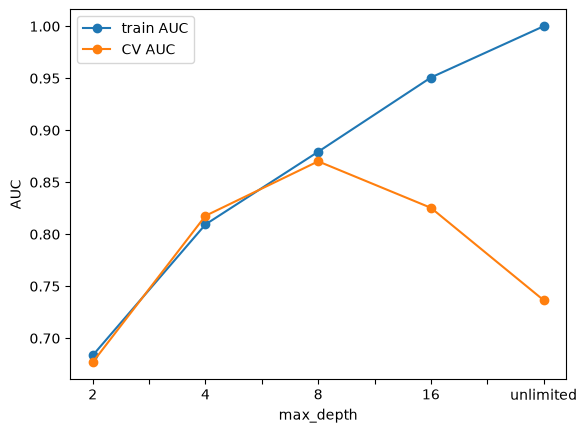

In [87]:
depth_table.plot(x="max_depth", y=["train AUC", "CV AUC"], marker="o", ylabel="AUC");

TODO (the assignment says explanations and predictions must be your own words):
- Depth 2 tree: bias or variance, and why (one sentence).
- Unlimited tree: bias or variance, and why (one sentence).
- Your prediction, written BEFORE running 2.2: which of bagging / boosting helps each tree more?

## 2.2

In [ ]:
# 2.2  Bagging and gradient boosting on the two trees from 2.1, plus a random forest
from sklearn.ensemble import BaggingClassifier

shallow = DecisionTreeClassifier(max_depth=2, random_state=42)
deep = DecisionTreeClassifier(max_depth=None, random_state=42)

models = {
    "bagging, depth-2 tree": BaggingClassifier(shallow, n_estimators=100, n_jobs=-1, random_state=42),
    "bagging, unlimited tree": BaggingClassifier(deep, n_estimators=25, n_jobs=-1, random_state=42),
    "boosting, depth-2 tree": GradientBoostingClassifier(max_depth=2, n_estimators=200, random_state=42),
    "boosting, unlimited tree": GradientBoostingClassifier(max_depth=None, n_estimators=10, random_state=42),  # fewer trees: unlimited trees are slow
    "random forest, 200 trees": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)}

rows, oof_scores = [], {}
for name, m in models.items():
    start = time.time()
    oof, aucs = cv_scores(make_pipeline(preprocess, m), logreg_score)   # logreg_score = predict_proba[:, 1]
    oof_scores[name] = oof
    t, cost = best_threshold(y_tr, oof)
    rows.append({"model": name, "CV AUC": np.mean(aucs), "best threshold": t, "total cost (€)": cost,
                 "cost per booking (€)": cost / len(y_tr), "seconds": time.time() - start})
ensemble_results = pd.DataFrame(rows).round(3)
ensemble_results

TODO: compare the results with your prediction from 2.1 and explain anything that surprised you. A wrong prediction with an honest, correct explanation gets the same marks as a right one.

## 2.3


In [ ]:
# 2.3  Top-10 features. best_boosted = the boosted model with the lowest CV cost in 2.2.
best_boosted = make_pipeline(preprocess, models["boosting, depth-2 tree"]).fit(X_tr, y_tr)
rf = make_pipeline(preprocess, models["random forest, 200 trees"]).fit(X_tr, y_tr)

names = preprocess.get_feature_names_out()
top10 = lambda m: pd.Series(m[-1].feature_importances_, index=names, name="importance").rename_axis("feature").nlargest(10).round(4)
pd.concat([top10(best_boosted).reset_index(), top10(rf).reset_index()], axis=1, keys=["boosted", "random forest"])

In [89]:
# Where do the nonrefundable deposits come from?
print(df.groupby("deposit_type")["is_canceled"].agg(["count", "mean"]).round(3))
nr = df[df["deposit_type"] == "Non Refund"]
for col in ["market_segment", "agent"]:
    print(nr.groupby(col)["is_canceled"].agg(["count", "mean"]).nlargest(5, "count").round(3))

# the same market segments with other deposit types
top_segments = nr["market_segment"].value_counts().index[:2]
df[df["market_segment"].isin(top_segments)].groupby(["market_segment", "deposit_type"])["is_canceled"].agg(["count", "mean"]).round(3)

              count   mean
deposit_type              
No Deposit    85251  0.267
Non Refund     1016  0.946
Refundable      107  0.243
                count   mean
market_segment              
Groups            643  0.958
Offline TA/TO     282  0.989
Corporate          64  0.703
Online TA          18  0.833
Direct              9  0.667
       count   mean
agent              
1        279  1.000
0        190  0.821
3         42  1.000
229       36  1.000
6         30  1.000


count   mean
market_segment deposit_type              
Groups         No Deposit     4090  0.154
               Non Refund      643  0.958
               Refundable       80  0.088
Offline TA/TO  No Deposit    13417  0.129
               Non Refund      282  0.989
               Refundable        4  0.500

TODO:
- The top-five features as plain-English statements the revenue director could act on.
- Your verdict on the non-refundable deposit result: would changing deposit policy reduce cancellations, or is something else going on?
- Why two good models (boosted vs random forest) can rank the same features differently.

## 3.1

In [90]:
# 3.1  10,000 NOT-cancelled bookings, sampled from the training split only (test set stays untouched)
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

features = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
            "adr", "total_of_special_requests", "booking_changes", "previous_bookings_not_canceled"]
train_all = X_train.assign(is_canceled=y_train)
S = train_all[train_all["is_canceled"] == 0].sample(10000, random_state=42)
F = S[features].astype(float)

# k=4 on raw vs standardised features
raw = KMeans(4, n_init=10, random_state=42).fit(F)
std = KMeans(4, n_init=10, random_state=42).fit(StandardScaler().fit_transform(F))

# how far apart are the 4 centroids along each feature?
pd.DataFrame({"variance": F.var(),
              "raw centroid spread": raw.cluster_centers_.std(axis=0),
              "standardised centroid spread": std.cluster_centers_.std(axis=0)}, index=features).round(2)

,variance,raw centroid spread,standardised centroid spread
lead_time,6614.76,96.71,0.63
stays_in_weekend_nights,1.02,0.28,0.56
stays_in_week_nights,3.86,0.74,0.65
adults,0.26,0.13,0.87
children,0.17,0.08,1.47
adr,2524.37,35.60,0.59
total_of_special_requests,0.74,0.14,0.28
booking_changes,0.55,0.10,0.17
previous_bookings_not_canceled,4.40,0.21,0.25


               skew  skew after log1p
adr        1.003620         -3.481886
lead_time  1.480121         -0.529857


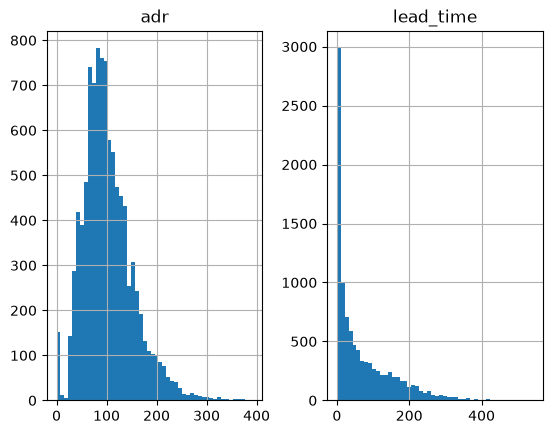

In [91]:
# Is standardising enough, or should we log first?
cols = ["adr", "lead_time"]
print(pd.DataFrame({"skew": F[cols].skew(), "skew after log1p": np.log1p(F[cols].clip(lower=0)).skew()}))
F[cols].hist(bins=50);

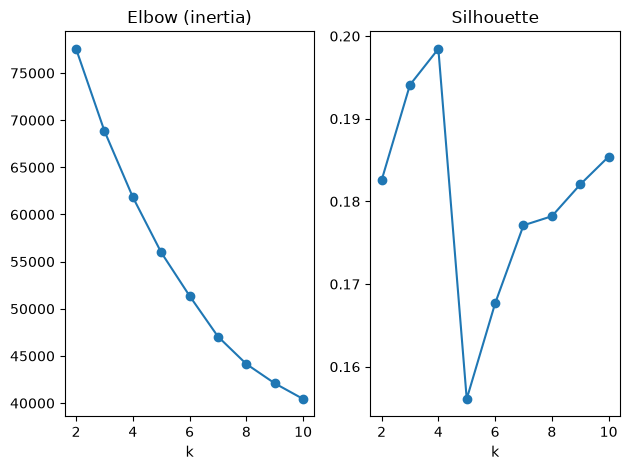

In [92]:
# DECISION: log first or not?
USE_LOG = False
Fc = np.log1p(F.clip(lower=0)) if USE_LOG else F
scaler = StandardScaler().fit(Fc)
Z = scaler.transform(Fc)

# elbow and silhouette for k = 2..10
ks = range(2, 11)
fits = [KMeans(k, n_init=10, random_state=42).fit(Z) for k in ks]
plt.subplot(1, 2, 1); plt.plot(ks, [f.inertia_ for f in fits], "o-"); plt.title("Elbow (inertia)"); plt.xlabel("k")
plt.subplot(1, 2, 2); plt.plot(ks, [silhouette_score(Z, f.labels_) for f in fits], "o-"); plt.title("Silhouette"); plt.xlabel("k")
plt.tight_layout();

In [93]:
# DECISION: your k. Then re-run k-means from 20 different starting points.
k = 4
runs = [KMeans(k, n_init=1, random_state=s).fit(Z) for s in range(20)]
inertias = np.array([r.inertia_ for r in runs])
print("inertia: min", inertias.min().round(1), "max", inertias.max().round(1))
final = min(runs, key=lambda r: r.inertia_)
labels = final.labels_

inertia: min 61838.1 max 65987.1


TODO: which feature takes over the raw clustering and why (distance formula); standardise vs log; what k the elbow and silhouette suggest and what each measures; your k and the business reason; how much inertia moved.

### 3.2

In [94]:
# 3.2  One-row profile per cluster
S2 = S.assign(cluster=labels)
profile = S2.groupby("cluster")[features].median().round(2)
profile["size"] = S2.groupby("cluster").size()
profile["share resort"] = S2.groupby("cluster")["hotel"].apply(lambda h: (h == "Resort Hotel").mean()).round(3)
profile["top market_segment"] = S2.groupby("cluster")["market_segment"].agg(lambda m: m.mode()[0])
profile

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,adr,total_of_special_requests,booking_changes,previous_bookings_not_canceled,size,share resort,top market_segment
cluster,,,,,,,,,,,,
0,158.0,2.0,5.0,2.0,0.0,89.94,1.0,0.0,0.0,2082,0.628,Online TA
1,29.0,1.0,2.0,2.0,0.0,99.00,1.0,0.0,0.0,5231,0.338,Online TA
2,56.0,1.0,2.0,2.0,1.0,148.50,1.0,0.0,0.0,798,0.362,Online TA
3,7.0,0.0,1.0,1.0,0.0,72.50,0.0,0.0,0.0,1889,0.356,Online TA


In [95]:
# Assign ALL training bookings (cancelled or not) to the nearest centroid, then compare cancel rates
T = train_all[features].astype(float)
T = np.log1p(T.clip(lower=0)) if USE_LOG else T
cluster_of = final.predict(scaler.transform(T))
table = pd.crosstab(cluster_of, train_all["is_canceled"])
table["cancel rate"] = (table[1] / (table[0] + table[1])).round(3)
table

is_canceled,0,1,cancel rate
row_0,,,
0,10374,5138,0.331
1,26125,9581,0.268
2,4038,2256,0.358
3,9581,2006,0.173


TODO: a name and one offer per cluster; the cluster you trust least and why; whether any segment cancels much more and what that adds beyond Part 2.

## 3.3

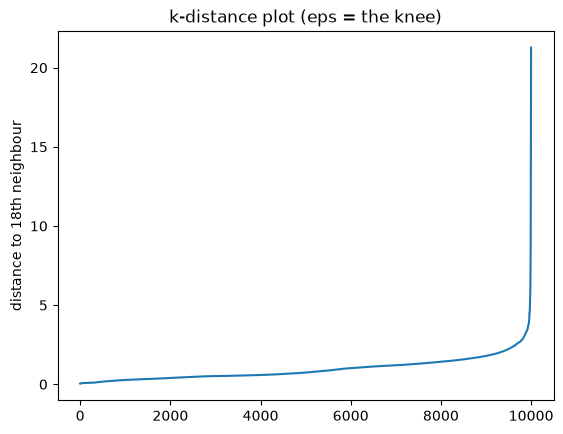

In [96]:
# 3.3  DBSCAN: MinPts = 2 x number of features, eps from the k-distance plot
min_pts = 2 * Z.shape[1]
kdist = np.sort(NearestNeighbors(n_neighbors=min_pts).fit(Z).kneighbors(Z)[0][:, -1])
plt.plot(kdist); plt.ylabel(f"distance to {min_pts}th neighbour"); plt.title("k-distance plot (eps = the knee)");

In [97]:
# DECISION: eps. The 95th percentile is only a stand-in; set it from the knee in the plot.
eps = np.percentile(kdist, 95)
db = DBSCAN(eps=eps, min_samples=min_pts).fit(Z)
print("eps", round(eps, 2), "| clusters:", len(set(db.labels_)) - (-1 in db.labels_), "| noise points:", (db.labels_ == -1).sum())
print("ARI (k-means vs DBSCAN):", round(adjusted_rand_score(labels, db.labels_), 3))
print("k-means silhouette:", round(silhouette_score(Z, labels), 3))

eps 2.23 | clusters: 3 | noise points: 193
ARI (k-means vs DBSCAN): 0.179
k-means silhouette: 0.199


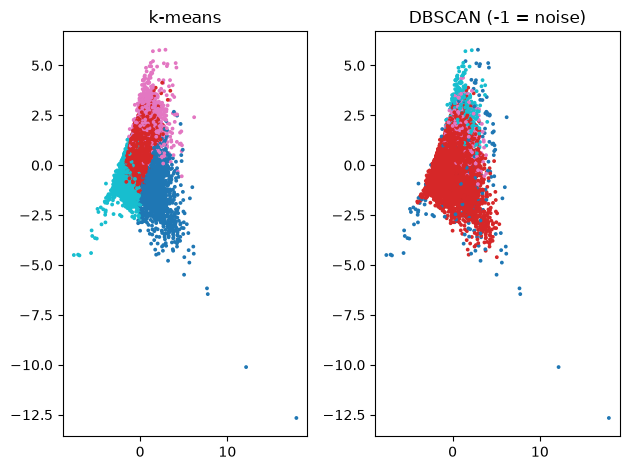

In [98]:
# 2D picture (PCA) of both clusterings
P = PCA(2, random_state=42).fit_transform(Z)
plt.subplot(1, 2, 1); plt.scatter(P[:, 0], P[:, 1], c=labels, s=3, cmap="tab10"); plt.title("k-means")
plt.subplot(1, 2, 2); plt.scatter(P[:, 0], P[:, 1], c=db.labels_, s=3, cmap="tab10"); plt.title("DBSCAN (-1 = noise)")
plt.tight_layout();

## 4.1
Final model and threshold, chosen from CV only.

In [ ]:
# 4.1  
# Chosen from CV only: the random forest from 2.2 has the lowest CV cost of all models in 1.3 and 2.2.
final_model = make_pipeline(preprocess, models["random forest, 200 trees"])
final_score, final_oof = logreg_score, oof_scores["random forest, 200 trees"]   # logreg_score = predict_proba[:, 1]
n_sub = None                                    # fit on all training rows
threshold, cv_cost = best_threshold(y_tr, final_oof)

def fit_and_score(Xa, ya, Xb):
    if n_sub:
        Xa, _, ya, _ = train_test_split(Xa, ya, train_size=n_sub, stratify=ya, random_state=42)
    return final_score(clone(final_model).fit(Xa, ya), Xb)

def summarize(y, score):
    pred = (score >= threshold).astype(int)
    cost = total_cost(y, pred)
    return {"AUC": roc_auc_score(y, score), "recall": recall_score(y, pred), "precision": precision_score(y, pred),
            "total cost (€)": cost, "cost per booking (€)": cost / len(y)}

def trivial(y):
    return {"overbook nobody": {"cost per booking (€)": 120 * (y == 1).sum() / len(y)},
            "overbook everybody": {"cost per booking (€)": 150 * (y == 0).sum() / len(y)}}

print("CV cost per booking at this threshold:", round(cv_cost / len(y_tr), 2))

# 1) random split: fit on all training rows, score the holdout test set once
random_score = fit_and_score(X_train, y_train, X_test)
random_row = summarize(y_test, random_score)
pd.DataFrame({"final model (random test split)": random_row, **trivial(y_test)}).round(3)

In [101]:
# 2) time split: train on arrivals in 2015-2016, test on 2017.
# arrival_date_year is set to 0 so the model cannot extrapolate from a year it never saw.
X_all = X.assign(arrival_date_year=0)
old = X["arrival_date_year"] <= 2016
time_score = fit_and_score(X_all[old], y[old], X_all[~old])
time_row = summarize(y[~old], time_score)
pd.DataFrame({"final model (train 2015-16, test 2017)": time_row, **trivial(y[~old])}).round(3)

,"final model (train 2015-16, test 2017)",overbook nobody,overbook everybody
AUC,0.774,NaN,NaN
recall,0.396,NaN,NaN
precision,0.700,NaN,NaN
total cost (€),981480.000,NaN,NaN
cost per booking (€),31.216,38.227,102.217


In [102]:
# What could make 2017 behave differently from 2016? Compare the years.
print(df.groupby("arrival_date_year").agg(cancel_rate=("is_canceled", "mean"), bookings=("is_canceled", "size"),
                                         months=("arrival_date_month", "nunique"), mean_lead_time=("lead_time", "mean")).round(3))
for col in ["hotel", "market_segment", "deposit_type"]:
    print(pd.crosstab(df["arrival_date_year"], df[col], normalize="index").round(3), "\n")

                   cancel_rate  bookings  months  mean_lead_time
arrival_date_year                                               
2015                     0.203     13089       6          58.656
2016                     0.264     41843      12          76.536
2017                     0.319     31442       8          93.839
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2015                    0.492         0.508
2016                    0.633         0.367
2017                    0.635         0.365 

market_segment     Aviation  Complementary  Corporate  Direct  Groups  \
arrival_date_year                                                       
2015                  0.000          0.011      0.063   0.162   0.100   
2016                  0.003          0.008      0.050   0.125   0.048   
2017                  0.003          0.006      0.039   0.136   0.048   

market_segment     Offline TA/TO  Online TA  Undefined  
arrival_date_year             

TODO: whether test cost is noticeably worse than CV cost and the most likely reason; which of the two test costs the revenue director should believe and why; the one thing in the data that could make 2017 differ from 2016.

## 4.2

In [103]:
# 4.2  Numbers for the memo. Savings vs overbooking nobody, per month.
months = df.groupby(["arrival_date_year", "arrival_date_month"]).ngroups     # months covered by the data
bookings_per_month = len(df) / months

def monthly(y, score):
    pred = (score >= threshold).astype(int)
    saved_per_booking = 120 * (y == 1).sum() / len(y) - total_cost(y, pred) / len(y)
    scale = bookings_per_month / len(y)
    return {"euros saved per month": saved_per_booking * bookings_per_month,
            "rooms overbooked per month": pred.sum() * scale,
            "cancellations caught per month": ((pred == 1) & (y == 1)).sum() * scale,
            "guests walked per month": ((pred == 1) & (y == 0)).sum() * scale}

print(months, "months of data,", round(bookings_per_month), "bookings per month")
pd.DataFrame({"random split": monthly(y_test, random_score), "time split": monthly(y[~old], time_score)}).round(0)

26 months of data, 3322 bookings per month


,random split,time split
euros saved per month,32792.0,23291.0
rooms overbooked per month,628.0,599.0
cancellations caught per month,470.0,419.0
guests walked per month,158.0,180.0


The memo is a separate PDF (two pages at most) and is yours to write. Numbers above, plus the segments from 3.2 and the cost results from 1.3 and 4.1, are the inputs.